# Group 03 — Week 1: Dataset & Baseline
**Topic:** Geometric Augmentation — Effect of Image Scaling / Zoom
**This week:** prepare the vehicle dataset, get it into clean YOLO format, visualise boxes, create train/val/test splits, and train the **no-augmentation baseline** on YOLOv8n, YOLOv11n and YOLOv26n.


## 1. Setup — install packages

In [ ]:
!pip install -q ultralytics
import ultralytics
ultralytics.checks()


Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.2/112.6 GB disk)


## 2. Upload the dataset zip
Go to [the dataset page on Kaggle](https://www.kaggle.com/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo), click **Download** to save the zip to your Mac (e.g. `vehicle-dataset-for-yolo.zip` in your Downloads folder), then run the cell below and select that file when the upload button appears.

This can take a few minutes depending on your internet connection — the file is a few hundred MB.


In [ ]:
from google.colab import files
import os

print("Select the dataset zip file you downloaded from Kaggle...")
uploaded = files.upload()

# Grab whatever filename was uploaded (in case it doesn't match exactly)
zip_filename = list(uploaded.keys())[0]
print(f"Uploaded: {zip_filename}")


Select the dataset zip file you downloaded from Kaggle...


Saving vehicle_dataset.zip to vehicle_dataset.zip
Uploaded: vehicle_dataset.zip


In [ ]:
import zipfile

os.makedirs('/content/raw_dataset', exist_ok=True)

with zipfile.ZipFile(zip_filename, 'r') as zf:
    zf.extractall('/content/raw_dataset')

print("Unzip done.")


Unzip done.


## 3. Inspect the raw folder structure
Kaggle zips vary slightly in layout. Run this first and **look at the printed tree** before trusting the path variables in the next cell — adjust them if your structure differs.


In [ ]:
import os

for root, dirs, files_ in os.walk('/content/raw_dataset'):
    depth = root.replace('/content/raw_dataset', '').count(os.sep)
    if depth > 3:
        continue
    indent = '  ' * depth
    print(f"{indent}{os.path.basename(root) or root}/  ({len(files_)} files)")


raw_dataset/  (0 files)
  vehicle dataset/  (1 files)
    train/  (0 files)
      labels/  (2100 files)
      images/  (2100 files)
    valid/  (0 files)
      labels/  (900 files)
      images/  (900 files)


## 4. Consolidate all images + labels into one pool
The published dataset only ships a train/valid split. We merge everything into one pool of image+label pairs, then create our **own clean 70/15/15 train/val/test split** in the next step (needed for the project's train/val/test requirement, and so every augmentation-intensity run in later weeks uses the identical split).

**Adjust `SEARCH_DIRS` below if cell 3's printout shows a different layout** (e.g. if images/labels sit directly under `raw_dataset/` rather than under `train/`, `valid/`).


In [ ]:
import glob, shutil, os

SEARCH_DIRS = ['/content/raw_dataset']  # widen/narrow based on what cell 3 printed

pool_dir = '/content/pool'
os.makedirs(f'{pool_dir}/images', exist_ok=True)
os.makedirs(f'{pool_dir}/labels', exist_ok=True)

img_exts = ('.jpg', '.jpeg', '.png')
all_images = []
for d in SEARCH_DIRS:
    for ext in img_exts:
        all_images += glob.glob(f'{d}/**/*{ext}', recursive=True)
        all_images += glob.glob(f'{d}/**/*{ext.upper()}', recursive=True)

print(f"Found {len(all_images)} candidate images")

paired = 0
for img_path in all_images:
    base = os.path.splitext(os.path.basename(img_path))[0]
    # label file usually sits in a sibling 'labels' folder with the same basename
    label_guess = img_path.replace('/images/', '/labels/')
    label_guess = os.path.splitext(label_guess)[0] + '.txt'
    if not os.path.exists(label_guess):
        # fallback: search anywhere for a matching .txt
        matches = glob.glob(f'/content/raw_dataset/**/{base}.txt', recursive=True)
        label_guess = matches[0] if matches else None

    if label_guess and os.path.exists(label_guess):
        shutil.copy(img_path, f'{pool_dir}/images/{base}{os.path.splitext(img_path)[1]}')
        shutil.copy(label_guess, f'{pool_dir}/labels/{base}.txt')
        paired += 1

print(f"Paired image+label files copied to pool: {paired}")


Found 3000 candidate images
Paired image+label files copied to pool: 3000


## 5. Define class names
Check the dataset's `data.yaml` / `classes.txt` / `obj.names` (visible in the cell 3 tree) to confirm these match — reorder if the index order differs.


In [ ]:
CLASS_NAMES = ['car', 'threewheel', 'bus', 'truck', 'motorbike', 'van']  # verify against dataset's own class list
print(f"{len(CLASS_NAMES)} classes: {CLASS_NAMES}")


6 classes: ['car', 'threewheel', 'bus', 'truck', 'motorbike', 'van']


## 6. Visualise a few samples with their bounding boxes (sanity check)

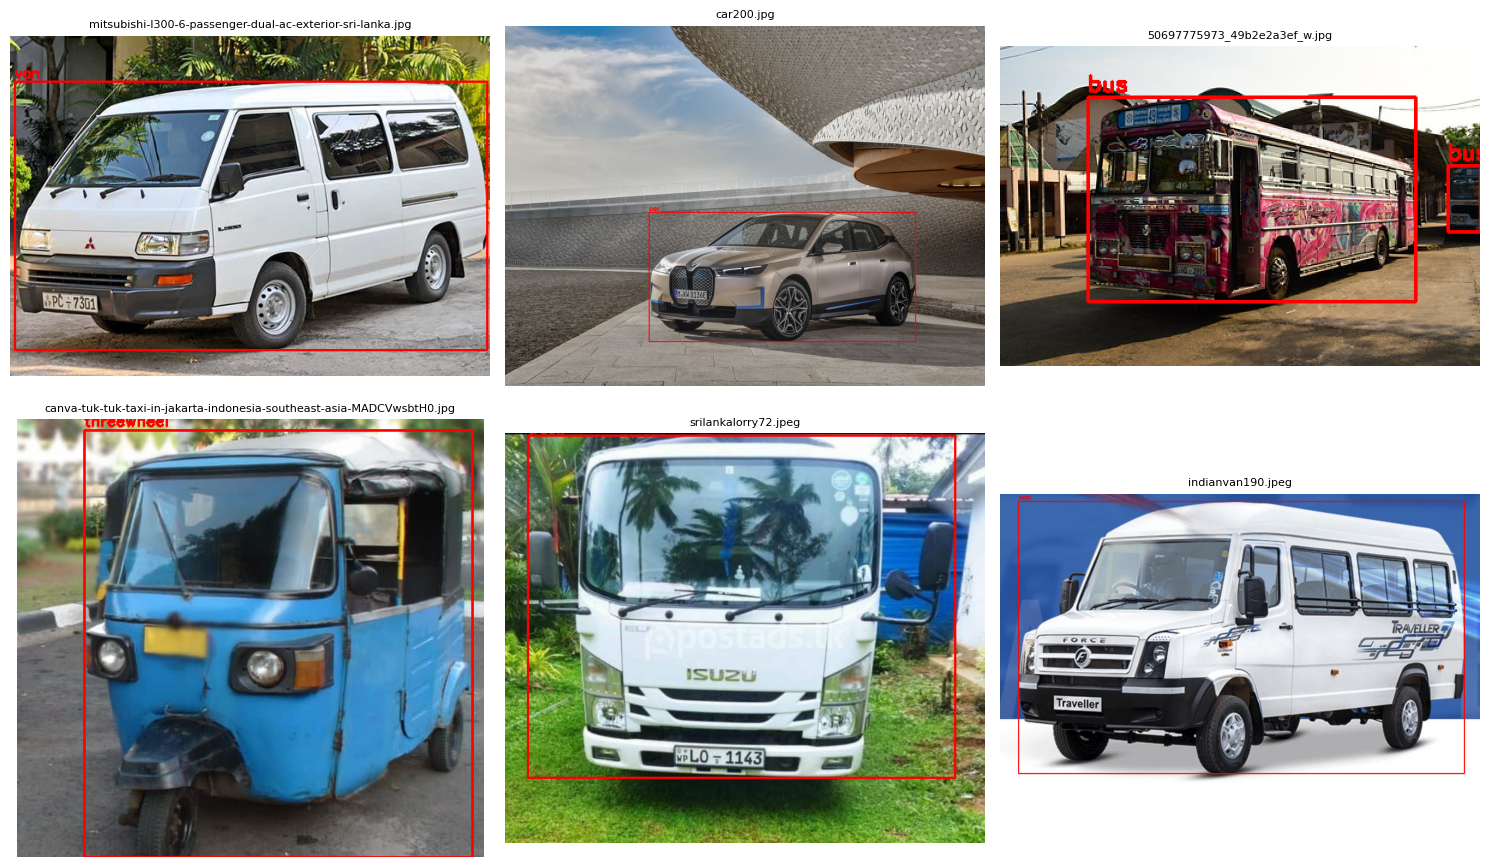

In [ ]:
import cv2, random
import matplotlib.pyplot as plt

def draw_yolo_boxes(img_path, label_path, class_names):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls, xc, yc, bw, bh = parts[:5]
                cls, xc, yc, bw, bh = int(cls), float(xc), float(yc), float(bw), float(bh)
                x1 = int((xc - bw/2) * w); y1 = int((yc - bh/2) * h)
                x2 = int((xc + bw/2) * w); y2 = int((yc + bh/2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
                label = class_names[cls] if cls < len(class_names) else str(cls)
                cv2.putText(img, label, (x1, max(y1-5, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,0,0), 2)
    return img

sample_imgs = random.sample(os.listdir(f'{pool_dir}/images'), min(6, len(os.listdir(f'{pool_dir}/images'))))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, fname in zip(axes.flatten(), sample_imgs):
    base = os.path.splitext(fname)[0]
    img = draw_yolo_boxes(f'{pool_dir}/images/{fname}', f'{pool_dir}/labels/{base}.txt', CLASS_NAMES)
    ax.imshow(img)
    ax.set_title(fname, fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig('/content/sample_boxes_check.png', dpi=150)
plt.show()


## 7. Create the train / val / test split (70 / 15 / 15)

In [ ]:
from sklearn.model_selection import train_test_split
import shutil, os

all_bases = [os.path.splitext(f)[0] for f in os.listdir(f'{pool_dir}/images')]
train_b, temp_b = train_test_split(all_bases, test_size=0.30, random_state=42)
val_b, test_b   = train_test_split(temp_b,   test_size=0.50, random_state=42)

splits = {'train': train_b, 'val': val_b, 'test': test_b}
DATASET_ROOT = '/content/dataset_split'

for split, bases in splits.items():
    os.makedirs(f'{DATASET_ROOT}/{split}/images', exist_ok=True)
    os.makedirs(f'{DATASET_ROOT}/{split}/labels', exist_ok=True)
    for base in bases:
        img_src = glob.glob(f'{pool_dir}/images/{base}.*')[0]
        ext = os.path.splitext(img_src)[1]
        shutil.copy(img_src, f'{DATASET_ROOT}/{split}/images/{base}{ext}')
        shutil.copy(f'{pool_dir}/labels/{base}.txt', f'{DATASET_ROOT}/{split}/labels/{base}.txt')
    print(f"{split}: {len(bases)} images")


train: 2100 images
val: 450 images
test: 450 images


## 8. Write `data.yaml` for Ultralytics

In [ ]:
yaml_content = f"""path: {DATASET_ROOT}
train: train/images
val: val/images
test: test/images

nc: {len(CLASS_NAMES)}
names: {CLASS_NAMES}
"""

with open(f'{DATASET_ROOT}/data.yaml', 'w') as f:
    f.write(yaml_content)

print(yaml_content)


path: /content/dataset_split
train: train/images
val: val/images
test: test/images

nc: 6
names: ['car', 'threewheel', 'bus', 'truck', 'motorbike', 'van']



## 9. Train BASELINE models (no augmentation) — YOLOv8n, YOLOv11n, YOLOv26n
All default Ultralytics augmentations (mosaic, mixup, hsv, flips, scale, translate, etc.) are explicitly switched **off** here so this is a true no-augmentation baseline — your Week 2+ scaling/zoom augmentation gets added on top of this same config later, changing only the `scale` parameter (and any custom scaling/zoom logic you implement).

Adjust `EPOCHS` down (e.g. 20) for a first quick test run before committing to a longer final run.


In [ ]:
from ultralytics import YOLO

EPOCHS = 30
IMGSZ = 640
BATCH = 16
DATA_YAML = f'{DATASET_ROOT}/data.yaml'

NO_AUG = dict(
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0,
    erasing=0.0,
)


In [ ]:
model_v8 = YOLO('yolov8n.pt')
results_v8 = model_v8.train(
    data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    name='baseline_yolov8n', project='/content/runs', **NO_AUG
)


New https://pypi.org/project/ultralytics/8.4.132 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_split/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

In [ ]:
model_v11 = YOLO('yolo11n.pt')
results_v11 = model_v11.train(
    data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    name='baseline_yolov11n', project='/content/runs', **NO_AUG
)


New https://pypi.org/project/ultralytics/8.4.132 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_split/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

In [ ]:
model_v26 = YOLO('yolo26n.pt')
results_v26 = model_v26.train(
    data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    name='baseline_yolov26n', project='/content/runs', **NO_AUG
)


New https://pypi.org/project/ultralytics/8.4.132 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_split/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

## 10. Evaluate each baseline on the held-out TEST split and collect metrics

In [ ]:
import pandas as pd

models = {
    'YOLOv8n': model_v8,
    'YOLOv11n': model_v11,
    'YOLOv26n': model_v26,
}

rows = []
for name, m in models.items():
    metrics = m.val(data=DATA_YAML, split='test')
    rows.append({
        'YOLO Version': name,
        'Precision': round(float(metrics.box.mp), 4),
        'Recall': round(float(metrics.box.mr), 4),
        'mAP50': round(float(metrics.box.map50), 4),
        'mAP50-95': round(float(metrics.box.map), 4),
    })

baseline_df = pd.DataFrame(rows)
baseline_df.to_csv('/content/baseline_metrics_week1.csv', index=False)
baseline_df


Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.5±27.9 MB/s, size: 157.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset_split/test/labels... 450 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 510.5it/s 0.9s
val: New cache created: /content/dataset_split/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 5.0it/s 5.8s
                   all        450        612      0.927      0.885      0.933      0.834
                   car         94        113      0.932      0.843      0.871      0.843
            threewheel         72        115      0.959      0.896      0.961      0.838
         

,YOLO Version,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n,0.9267,0.8851,0.9329,0.8337
1,YOLOv11n,0.9131,0.8735,0.9189,0.8038
2,YOLOv26n,0.9370,0.8469,0.9176,0.8283


In [ ]:
!zip -r /content/week1_results.zip /content/runs /content/sample_boxes_check.png /content/baseline_metrics_week1.csv

  adding: content/runs/ (stored 0%)
  adding: content/runs/baseline_yolov11n/ (stored 0%)
  adding: content/runs/baseline_yolov11n/val_batch1_pred.jpg (deflated 7%)
  adding: content/runs/baseline_yolov11n/BoxP_curve.png (deflated 13%)
  adding: content/runs/baseline_yolov11n/train_batch1.jpg (deflated 10%)
  adding: content/runs/baseline_yolov11n/results.png (deflated 7%)
  adding: content/runs/baseline_yolov11n/val_batch2_pred.jpg (deflated 9%)
  adding: content/runs/baseline_yolov11n/BoxF1_curve.png (deflated 10%)
  adding: content/runs/baseline_yolov11n/train_batch2641.jpg (deflated 8%)
  adding: content/runs/baseline_yolov11n/BoxR_curve.png (deflated 11%)
  adding: content/runs/baseline_yolov11n/results.csv (deflated 60%)
  adding: content/runs/baseline_yolov11n/train_batch2640.jpg (deflated 10%)
  adding: content/runs/baseline_yolov11n/labels.jpg (deflated 27%)
  adding: content/runs/baseline_yolov11n/args.yaml (deflated 54%)
  adding: content/runs/baseline_yolov11n/val_batch1_la

In [ ]:
from google.colab import files
files.download('/content/week1_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>